# 04 — Part-time vs full-time: an availability read

**Step 13 (M3).** The plan was to compare *skill demand* across employment types.
The data won't support that: only **19** of 1189 distinct jobs are part-time, and
only **7** of those match any taxonomy skill — an n=7 ranking is anecdote, not
signal.

So we reframe (as step 11b did): the honest, defensible question is **how rare
part-time data work is, and where it shows up** — broken down by role and by
source. The by-source cut doubles as evidence for why the multi-source add
mattered: Adzuna barely reports employment type; Remotive tags every job.

## What this notebook does and doesn't claim

- **Does:** show that part-time data roles are rare (**19 / 1189 ≈ 1.6%**) and that employment-type reporting is a *source* artefact — Adzuna leaves it blank on ~65% of its jobs, Remotive tags all of its.
- **Doesn't:** rank skills by employment type. Only **7** part-time jobs mention any taxonomy skill, so the skills list further down is anecdote (colour), not a demand signal — a top-N on n=7 would be noise dressed as a finding.
- **Small-n everywhere in the part-time column:** the by-role part-time rates rest on 0–11 jobs each; read them as "where the few part-time roles sit", not precise rates. And absolute counts are still floored by Adzuna's 500-char truncation (step 11b) — a job whose description is cut off can't reveal a part-time tag it never stated.

In [1]:
import sqlite3
import sys
from pathlib import Path

import pandas as pd

# notebooks/ -> repo root on sys.path so `import jobskills` resolves.
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from jobskills import config

with sqlite3.connect(config.SQLITE_PATH) as conn:
    jobs = pd.read_sql_query(
        "SELECT id, role_query, source, contract_time, "
        "       COALESCE(dedup_key, 'id:' || id) AS ident "
        "FROM jobs",
        conn,
    )
    hits = pd.read_sql_query("SELECT posting_id, skill FROM skill_hits", conn)

len(jobs), len(hits)

(1423, 1014)

In [2]:
# Collapse to one row per distinct job. Unlike notebook 03 we do NOT keep a job
# per role — employment type is a property of the job itself, so we want each
# job once. keep='first' is arbitrary but safe: a job's contract_time is the same
# across its duplicate rows within a source (same id), and cross-source dedup
# collisions were 0 (step 10), so there's nothing to reconcile.
d = jobs.drop_duplicates(subset="ident").copy()

# Adzuna leaves contract_time blank on most jobs; label that honestly as
# 'unknown' instead of letting an empty string masquerade as a category.
d["employment"] = d["contract_time"].replace("", "unknown").fillna("unknown")

# Same BI merge as notebook 03 so the by-role cut lines up across notebooks.
BI_QUERIES = {"business intelligence analyst", "business intelligence developer"}
d["role"] = d["role_query"].where(~d["role_query"].isin(BI_QUERIES), "bi")

d["employment"].value_counts()

employment
unknown      750
full_time    415
part_time     19
contract       3
freelance      2
Name: count, dtype: int64

In [3]:
# --- By source: who even reports employment type? ---------------------------
# crosstab counts distinct jobs in each (source, employment) cell. normalize="index"
# turns each source's row into proportions, so we read "what fraction of Adzuna
# jobs carry each tag" vs the same for Remotive.
by_source = pd.crosstab(d["source"], d["employment"])
by_source_pct = (pd.crosstab(d["source"], d["employment"], normalize="index") * 100).round(1)

print("Distinct jobs by source x employment:")
print(by_source)
print("\nRow % (within each source):")
by_source_pct

Distinct jobs by source x employment:
employment  contract  freelance  full_time  part_time  unknown
source                                                        
adzuna             0          0        391         15      750
remotive           3          2         24          4        0

Row % (within each source):


employment,contract,freelance,full_time,part_time,unknown
source,,,,,
adzuna,0.0,0.0,33.8,1.3,64.9
remotive,9.1,6.1,72.7,12.1,0.0


In [4]:
# --- Where part-time concentrates, by role ----------------------------------
# Part-time rate per role = part-time jobs / all jobs in that role. Tiny counts,
# so we show the raw numerator alongside the % to keep the reader honest.
by_role = d.groupby("role").agg(
    total=("ident", "size"),
    part_time=("employment", lambda s: (s == "part_time").sum()),
)
by_role["part_time_pct"] = (by_role["part_time"] / by_role["total"] * 100).round(1)
by_role.sort_values("part_time_pct", ascending=False)

,total,part_time,part_time_pct
role,,,
data analyst,526,11,2.1
data scientist,443,7,1.6
analytics engineer,185,1,0.5
bi,35,0,0.0


In [5]:
# --- The part-time skills, as anecdote (NOT a ranking) ----------------------
# Only 7 part-time jobs match any skill, so this is a listing for colour, not a
# demand metric. We join the part-time job idents to their hits and just show
# which skills appeared and in how many of the (few) jobs.
pt_idents = set(d.loc[d["employment"] == "part_time", "ident"])
pt_hits = (
    hits.merge(d[["id", "ident"]], left_on="posting_id", right_on="id")
    .loc[lambda x: x["ident"].isin(pt_idents), ["ident", "skill"]]
    .drop_duplicates()
)
n_pt_with_skills = pt_hits["ident"].nunique()
print(f"{n_pt_with_skills} of {len(pt_idents)} part-time jobs mention any taxonomy skill\n")
pt_hits["skill"].value_counts()

7 of 19 part-time jobs mention any taxonomy skill



skill
ai                    4
machine learning      1
statistics            1
data visualization    1
r                     1
Name: count, dtype: int64

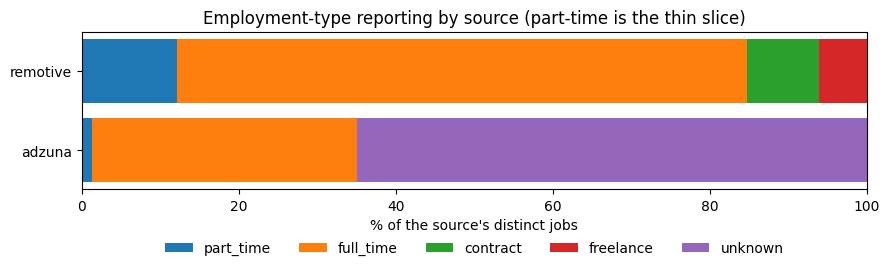

In [6]:
import matplotlib.pyplot as plt

# Stacked horizontal bars of the employment mix within each source. Row-normalised
# so both bars are full width (100%) and the eye compares composition, not volume —
# the point is Adzuna's bar is mostly 'unknown' while Remotive's isn't.
order = ["part_time", "full_time", "contract", "freelance", "unknown"]
plot_df = by_source_pct.reindex(columns=order)

fig, ax = plt.subplots(figsize=(9, 3))
left = pd.Series(0.0, index=plot_df.index)  # running left edge for stacking
for col in order:
    ax.barh(plot_df.index, plot_df[col], left=left, label=col)
    left += plot_df[col]

ax.set_xlabel("% of the source's distinct jobs")
ax.set_title("Employment-type reporting by source (part-time is the thin slice)")
ax.legend(ncol=5, bbox_to_anchor=(0.5, -0.25), loc="upper center", frameon=False)
fig.tight_layout()
plt.show()